# 03 — Evaluation protocol and naive baselines

Before any real model, we fix **how** every model will be judged, so that all later comparisons are fair:

1. the forecast windows (where forecasts start);
2. which series are scored in each window, frozen to disk;
3. the metrics, checked on small examples where the answer is known;
4. three naive forecasts that any real model must beat.

In [1]:
%load_ext autoreload
%autoreload 2

from datetime import timedelta

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import ARTIFACTS_DIR, roster_name
from m5_chronos2.evaluation import actuals, check_series, make_windows
from m5_chronos2.metrics import (
    HORIZON_BUCKETS,
    QUANTILE_LEVELS,
    join_truth,
    quantile_column,
    score,
)
from m5_chronos2.baselines import moving_average_forecast, seasonal_naive_forecast, zero_forecast
from m5_chronos2.plots import MUTED_TEXT_COLOR, index_plot, use_blog_style

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42

MIN_HISTORY_DAYS = 56   # a series needs 8 weeks on sale before the origin to be scored

In [3]:
NAME = roster_name(SAMPLE_SIZE, SEED)
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)

PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(exist_ok=True)

## 1. The forecast windows

- **validation**: used for every choice we make later (features, context length, fine-tuning);
- **test**: the last 28 days of the data, used only for the final comparison. Looking at it to make
  choices would make the final score optimistic.

In [4]:
windows = make_windows()
windows

role,origin,first_forecast_day,last_forecast_day
str,date,date,date
"""validation""",2016-03-27,2016-03-28,2016-04-24
"""test""",2016-04-24,2016-04-25,2016-05-22


## 2. Which series are scored?

A (series, window) pair is scored only if:
1. the series has at least `MIN_HISTORY_DAYS` days on sale before the origin;
2. no day of the forecast window is missing (the item is on sale every day);
3. the series sells at least one unit in the window (otherwise WMAPE and WQL divide by zero).

The count removed by each condition is reported separately, so a change in the number of scored series
is always visible.

In [5]:
all_checks = []
for origin in windows["origin"].to_list():
    checks = check_series(sales, origin, MIN_HISTORY_DAYS)
    all_checks.append(checks)

    n_total = checks.height
    n_short_history = (~checks["enough_history"]).sum()
    n_missing = (checks["enough_history"] & ~checks["window_fully_observed"]).sum()
    n_all_zero = (checks["enough_history"] & checks["window_fully_observed"] & ~checks["window_not_all_zero"]).sum()
    n_scored = checks["is_scored"].sum()

    print(f"Origin {origin}: {n_total} series")
    print(f"  removed, too little history:        {n_short_history}")
    print(f"  removed, missing days in window:    {n_missing}")
    print(f"  removed, no sale in window:         {n_all_zero}")
    print(f"  scored:                             {n_scored}")

checks = pl.concat(all_checks)

Origin 2016-03-27: 500 series
  removed, too little history:        0
  removed, missing days in window:    0
  removed, no sale in window:         27
  scored:                             473
Origin 2016-04-24: 500 series
  removed, too little history:        0
  removed, missing days in window:    0
  removed, no sale in window:         15
  scored:                             485


Freeze the result: the first run writes the evaluation roster, every later run reads it back.

In [6]:
eval_roster_path = ARTIFACTS_DIR / f"eval_roster_{NAME}.parquet"

if eval_roster_path.exists():
    eval_roster = pl.read_parquet(eval_roster_path)
    print(f"Read the frozen evaluation roster: {eval_roster.height} (origin, series) pairs")
else:
    eval_roster = (
        checks.filter(pl.col("is_scored"))
        .join(windows.select("origin", "role"), on="origin", how="left")
        .select("role", "origin", "id")
        .sort("origin", "id")
    )
    eval_roster.write_parquet(eval_roster_path)
    print(f"Evaluation roster saved: {eval_roster.height} (origin, series) pairs")

eval_roster.group_by("role").agg(pl.len().alias("n_series"))

Evaluation roster saved: 958 (origin, series) pairs


role,n_series
str,u32
"""validation""",473
"""test""",485


## 3. The metrics, checked on known answers

For one quantile level $q$, the quantile loss of a forecast $\hat y_q$ is

$$
L_q(y, \hat y_q) = \begin{cases} q\,(y - \hat y_q) & \text{if } y \ge \hat y_q \text{ (under-prediction)}\\ (1-q)\,(\hat y_q - y) & \text{otherwise (over-prediction)} \end{cases}
$$

| metric | definition | what it tells |
|---|---|---|
| MAE | mean of $\lvert y - \hat y\rvert$ | error in units sold |
| WMAPE | $100 \cdot \sum \lvert y - \hat y\rvert / \sum \lvert y\rvert$ | scale-free, survives zeros: the headline |
| P90 | 90th percentile of $\lvert y - \hat y\rvert$ | the bad days |
| WQL | mean over $q \in \{0.1, \dots, 0.9\}$ of $2 \sum L_q / \sum \lvert y\rvert$ | quality of the whole forecast distribution |
| RQL | $100 \cdot \sum L_{0.2} / \sum \lvert y\rvert$ | over-prediction costs 4 times more than under-prediction |

Sums run over every scored (series, day) pair. Three checks with known results:

In [7]:
y_toy = [0.0, 2.0, 4.0]

def toy_forecast(values):
    table = pl.DataFrame({"id": ["a", "a", "b"], "y": y_toy, "y_pred": values})
    return table.with_columns([pl.col("y_pred").alias(quantile_column(q)) for q in QUANTILE_LEVELS])

# 1. A perfect forecast has zero error everywhere.
perfect = score(toy_forecast(y_toy))
assert all(perfect[m][0] == 0 for m in ["MAE", "WMAPE", "P90", "WQL", "RQL"])

# 2. Always predicting 0: WMAPE = 100, WQL = 2 x mean(q) = 1, RQL = 100 x 0.2 = 20.
zero = score(toy_forecast([0.0, 0.0, 0.0]))
assert np.isclose(zero["WMAPE"][0], 100) and np.isclose(zero["WQL"][0], 1.0) and np.isclose(zero["RQL"][0], 20)

# 3. For a point forecast (all quantiles equal), WQL = WMAPE / 100.
point = score(toy_forecast([1.0, 1.0, 1.0]))
assert np.isclose(point["WQL"][0], point["WMAPE"][0] / 100)

print("All metric checks passed")
pl.concat([perfect, zero, point]).with_columns(pl.Series("forecast", ["perfect", "zero", "constant 1"]))

All metric checks passed


n_series,MAE,WMAPE,P90,WQL,RQL,forecast
u32,f64,f64,f64,f64,f64,str
2,0.0,0.0,0.0,0.0,0.0,"""perfect"""
2,2.0,100.0,4.0,1.0,20.0,"""zero"""
2,1.666667,83.333333,3.0,0.833333,26.666667,"""constant 1"""


Check 3 matters: a model that only gives a point forecast gets WQL = WMAPE / 100. A probabilistic model can
do better than that only if its quantiles carry real information about the uncertainty.

## 4. Three naive baselines

- **zero**: always 0 units. With intermittent series, it is not as absurd as it sounds;
- **seasonal naive**: repeat the last observed week;
- **moving average**: the mean daily sales of the last 28 days, flat over the horizon.

Forecasts are saved in the standard format, one file per model, like every future model.

In [8]:
baselines = {"zero": [], "seasonal_naive": [], "moving_average_28d": []}

for origin in windows["origin"].to_list():
    ids = eval_roster.filter(pl.col("origin") == origin)["id"].to_list()
    baselines["zero"].append(zero_forecast(ids, origin))
    baselines["seasonal_naive"].append(seasonal_naive_forecast(sales, ids, origin))
    baselines["moving_average_28d"].append(moving_average_forecast(sales, ids, origin, window_days=28))

predictions = {}
for model, parts in baselines.items():
    predictions[model] = pl.concat(parts)
    predictions[model].write_parquet(PREDICTIONS_DIR / f"{model}_{NAME}.parquet")

predictions["seasonal_naive"].head()

id,origin,date,y_pred,q0.1,q0.2,q0.3,q0.4,q0.5,q0.6,q0.7,q0.8,q0.9
str,date,date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-29,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-30,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-04-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Scores

Overall, per window. Only the validation window is used to make decisions.

In [9]:
scored = {model: join_truth(forecast, truth, eval_roster) for model, forecast in predictions.items()}

overall = pl.concat([
    score(table.join(windows.select("origin", "role"), on="origin"), by="role").with_columns(pl.lit(model).alias("model"))
    for model, table in scored.items()
])
overall.select("role", "model", "n_series", "MAE", "WMAPE", "P90", "WQL", "RQL").sort("role", "WMAPE")

role,model,n_series,MAE,WMAPE,P90,WQL,RQL
str,str,u32,f64,f64,f64,f64,f64
"""test""","""moving_average_28d""",485,0.963718,77.58187,2.178571,0.775819,37.974645
"""test""","""seasonal_naive""",485,1.176215,94.688482,3.0,0.946885,46.04778
"""test""","""zero""",485,1.242194,100.0,3.0,1.0,20.0
"""validation""","""moving_average_28d""",473,0.991549,79.588312,2.285714,0.795883,39.114156
"""validation""","""seasonal_naive""",473,1.202658,96.533333,3.0,0.965333,46.572121
"""validation""","""zero""",473,1.245847,100.0,3.0,1.0,20.0


By horizon bucket, on the validation window. Baselines are drawn in gray: color is kept for the real models.

/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_3833/1051549744.py:19: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


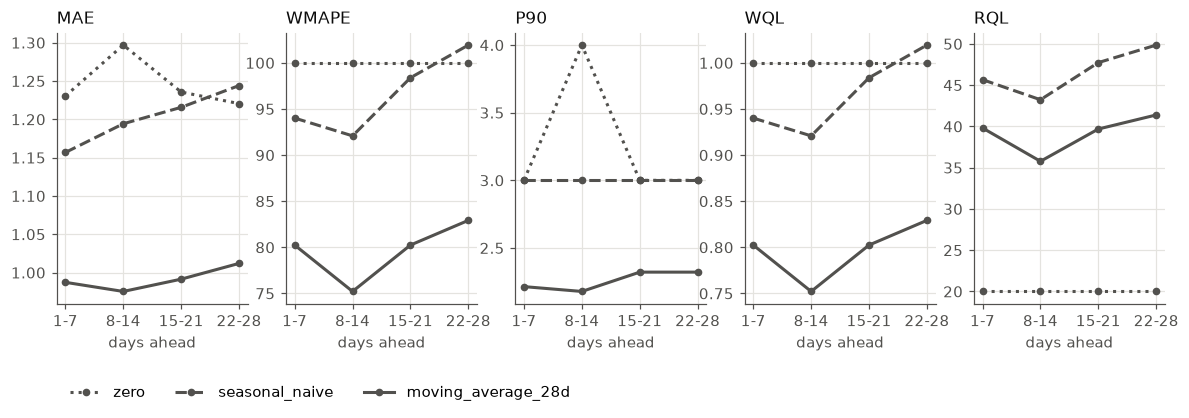

In [10]:
VALIDATION_ORIGIN = windows.filter(pl.col("role") == "validation")["origin"][0]
line_styles = {"zero": ":", "seasonal_naive": "--", "moving_average_28d": "-"}
bucket_names = list(HORIZON_BUCKETS)
metrics_to_plot = ["MAE", "WMAPE", "P90", "WQL", "RQL"]

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(13, 3.2))
for model, table in scored.items():
    by_bucket = score(table.filter(pl.col("origin") == VALIDATION_ORIGIN), by="horizon_bucket")
    for ax, metric in zip(axes, metrics_to_plot):
        ax.plot(range(len(bucket_names)), by_bucket[metric].to_numpy(), color=MUTED_TEXT_COLOR,
                linestyle=line_styles[model], marker="o", markersize=4, label=model)

for ax, metric in zip(axes, metrics_to_plot):
    ax.set_title(metric, loc="left")
    ax.set_xticks(range(len(bucket_names)))
    ax.set_xticklabels([f"{first}-{last}" for first, last in HORIZON_BUCKETS.values()])
    ax.set_xlabel("days ahead")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.25), ncol=3)
fig.tight_layout()
plt.show()

## 6. Series by series: seasonal naive vs moving average

Overall scores can hide a few series carrying the whole difference. The index plot shows each series'
relative difference in WQL, series sorted by sales volume in the window.

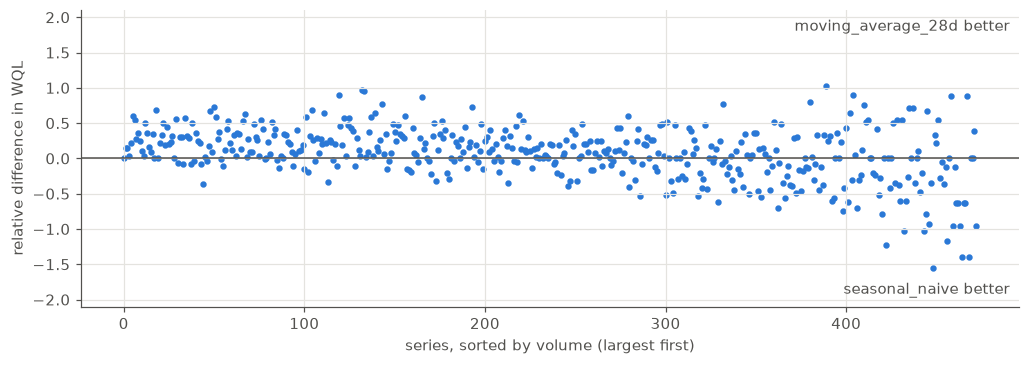

moving_average_28d has the lower WQL on 61% of series


In [11]:
def per_series_scores(model):
    table = scored[model].filter(pl.col("origin") == VALIDATION_ORIGIN)
    return score(table, by="id").select("id", pl.col("WQL").alias(f"WQL_{model}"))

volume = (
    truth.join(eval_roster.filter(pl.col("origin") == VALIDATION_ORIGIN), on="id")
    .filter(pl.col("date") > VALIDATION_ORIGIN, pl.col("date") <= VALIDATION_ORIGIN + timedelta(days=28))
    .group_by("id").agg(pl.col("y").sum().alias("volume"))
)
per_series = (
    per_series_scores("seasonal_naive")
    .join(per_series_scores("moving_average_28d"), on="id")
    .join(volume, on="id")
)

fig, ax = plt.subplots(figsize=(11, 3.5))
share = index_plot(ax, per_series, "WQL", "seasonal_naive", "moving_average_28d", order_by="volume")
plt.show()
print(f"moving_average_28d has the lower WQL on {share:.0%} of series")

## Notes

*Your observations here.*